# Bayesian Factorization of the Lung Cancer Data with the MGP Prior

This notebook analyzes `lung.npy` with the repository's JAX `mgp` interface, adapting the supplied lung-cancer workflow to the multiplicative gamma process (MGP) shrinkage prior of Bhattacharya and Dunson (2011). The model is $x_i=B\eta_i+\epsilon_i$, with a fixed overfitted truncation level $K=50$.

The analysis compares exact Gibbs sampling and deterministic CAVI. It covers fitting diagnostics, factor selection using 95% marginal intervals, Rotation-Sign-Permutation (RSP) alignment, loading-column norms, and scatter plots of the first two factor scores for four sample groups. Factor selection is performed in the original prior coordinates; RSP is used only to obtain a consistent orientation for visualization.

In [1]:
# CPU/GPU selection: run this cell before importing jax or mgp elsewhere.
# After changing MODE, restart the kernel and run all cells from the top.
import os

MODE = "cpu"
if MODE not in {"cpu", "gpu"}:
    raise ValueError('MODE must be "cpu" or "gpu".')
os.environ["JAX_PLATFORMS"] = "cpu" if MODE == "cpu" else "cuda,cpu"

import jax

backend = jax.default_backend()
if backend != MODE:
    raise RuntimeError("Device mode has changed: restart the kernel and run all cells.")
print("Backend:", backend)
print("Devices:", jax.devices())

Backend: cpu
Devices: [CpuDevice(id=0)]


## 1. Data and Shared Settings

The data comprise 56 samples and 5,000 genes. The samples are ordered as Carcinoid (20), Colon (13), Normal (17), and Small cell (6). The stored matrix is already centered and standardized to unit population variance in float64, so both estimators use `center=False, standardize=False` and no further rescaling is applied.

Both methods use the same MGP prior: `nu=3`, `a1=2.1`, `a2=3.1`, `a_sigma=1`, and `b_sigma=1`. The increasing column-wise shrinkage allows redundant columns of the overfitted loading matrix to be suppressed.

In [2]:
import sys
import time
from pathlib import Path

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np

try:
    root = Path(__file__).resolve().parents[1]
except NameError:
    root = None
if root is None or not (root / "mgp" / "__init__.py").is_file():
    root = next(
        (d for d in (Path.cwd(), *Path.cwd().parents)
         if (d / "mgp" / "__init__.py").is_file()),
        None,
    )
if root is None:
    raise FileNotFoundError("Could not locate the repository root containing mgp/.")
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from mgp import CaviMGP, GibbsMGP

K = 50
LEVEL = 0.95
SEED = 2026
MGP_PRIOR = dict(nu=3.0, a1=2.1, a2=3.1, a_sigma=1.0, b_sigma=1.0)
X = np.load(root / "lung" / "lung.npy", allow_pickle=False)
if X.shape != (56, 5000):
    raise ValueError(f"Expected X.shape == (56, 5000), got {X.shape}.")
if not np.isfinite(X).all():
    raise ValueError("X contains NaN or infinity.")

GROUPS = (
    ("Carcinoid", 0, 20, "orange", "s"),
    ("Colon", 20, 33, "blue", "o"),
    ("Normal", 33, 50, "green", "^"),
    ("Small cell", 50, 56, "black", "*"),
)
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 140,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 10,
})
np.set_printoptions(precision=4, suppress=True, linewidth=150)

population_sd = X.std(axis=0)
print(f"Repository: {root}")
print(f"X: {X.shape}, dtype={X.dtype}, range=({X.min():.4f}, {X.max():.4f})")
print(f"Max |column mean|: {np.abs(X.mean(axis=0)).max():.3e}")
print(f"Population SD range: ({population_sd.min():.6f}, {population_sd.max():.6f})")
print(f"K={K}, credible level={LEVEL}, seed={SEED}")
print("MGP prior:", MGP_PRIOR)

Repository: C:\Users\kexio\Desktop\GitHub\MGP_BFM
X: (56, 5000), dtype=float64, range=(-6.6776, 7.1188)
Max |column mean|: 8.921e-17
Population SD range: (1.000000, 1.000000)
K=50, credible level=0.95, seed=2026
MGP prior: {'nu': 3.0, 'a1': 2.1, 'a2': 3.1, 'a_sigma': 1.0, 'b_sigma': 1.0}


## 2. CAVI Fitting and ELBO Diagnostics

Each CAVI sweep updates the loadings, factor scores, noise variances, local shrinkage, and coupled global shrinkage factors in sequence. The closed-form ELBO is evaluated after every complete sweep. Here, `tol=0.1` with a maximum of 1,000 sweeps; `drop_budget=0.5` independently rejects an excessive ELBO decrease.

In [3]:
t0 = time.perf_counter()
vi = CaviMGP(
    K=K,
    **MGP_PRIOR,
    center=False,
    standardize=False,
    precision="float64",
    max_iter=1000,
    tol=1e-1,
    drop_budget=0.5,
    verbose=False,
).fit(X)
vi_wall = time.perf_counter() - t0

assert vi.mu_.shape == (X.shape[1], K)
assert vi.W_.shape == (X.shape[0], K)
assert vi.V_.shape == (X.shape[1], K, K)
assert vi.Phi_.shape == (K, K)
assert len(vi.elbo_) == vi.n_iter_ + 1
assert vi.stop_reason_ in {"tol", "max_iter"}
for values in (vi.mu_, vi.V_, vi.W_, vi.Phi_, vi.beta_, vi.beta_omega_, vi.beta_delta_):
    assert np.isfinite(values).all()
assert np.isfinite(vi.elbo_).all()
print(
    f"CAVI: converged={vi.converged_} ({vi.stop_reason_}), "
    f"sweeps={vi.n_iter_}, final ELBO={vi.elbo_[-1]:.4f}"
)
print(
    f"CAVI timing: compile={vi.compile_sec_:.2f}s, "
    f"loop={vi.runtime_sec_:.2f}s, wall={vi_wall:.2f}s, "
    f"precision={vi.precision_used_}"
)

CAVI: converged=False (max_iter), sweeps=1000, final ELBO=-323561.6906
CAVI timing: compile=0.49s, loop=256.90s, wall=260.29s, precision=float64


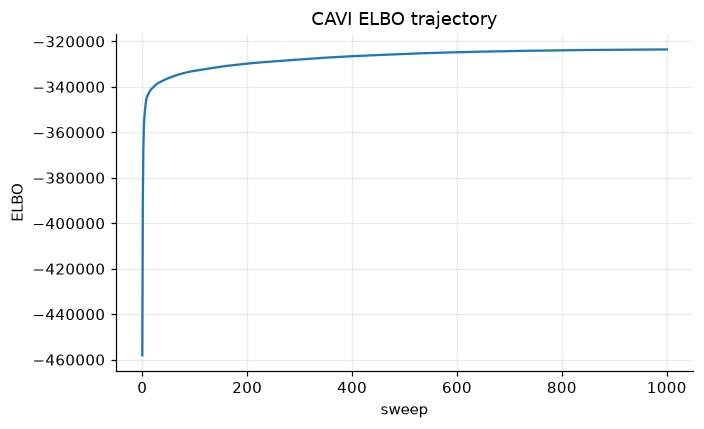

In [4]:
fig, ax = plt.subplots(figsize=(6.5, 4.0))
vi.plot_elbo(ax=ax, show=False, title="CAVI ELBO trajectory")
plt.show()

## 3. Gibbs Posterior Sampling and ESS

The Gibbs sampler runs 20,000 sweeps, discards the first 10,000 as burn-in, and retains every 10th draw thereafter, yielding 1,000 posterior draws. ESS is computed from the raw, unaligned draws. To bound ArviZ's temporary memory usage, the loading and noise-variance diagnostics use a deterministic subset containing every 25th gene; factor selection still uses all 5,000 genes.

The implementation uses a fixed truncation level and fixed `a1`/`a2`; it does not include the paper's adaptive truncation or the Metropolis-Hastings update of those two hyperparameters.

In [5]:
t0 = time.perf_counter()
gs = GibbsMGP(
    K=K,
    **MGP_PRIOR,
    center=False,
    standardize=False,
    precision="float32",
    n_iter=20000,
    burn_in=10000,
    thin=10,
    seed=SEED,
    graph=False,
    verbose=True,
).fit(X)
gs_wall = time.perf_counter() - t0

S = gs.B_samples_.shape[0]
assert S == 1000
assert gs.B_samples_.shape == (S, X.shape[1], K)
assert gs.sigma2_samples_.shape == (S, X.shape[1])
assert np.isfinite(gs.B_samples_).all()
assert np.isfinite(gs.sigma2_samples_).all()
assert (gs.sigma2_samples_ > 0).all()
print(f"Gibbs: kept={S}, seed={gs.seed_}, precision={gs.precision_used_}")
print(f"Loading draws: {gs.B_samples_.shape}; noise draws: {gs.sigma2_samples_.shape}")
print(
    f"Gibbs timing: loop={gs.runtime_sec_:.2f}s, wall={gs_wall:.2f}s, "
    f"mean={1e3 * gs.runtime_sec_ / gs.n_iter:.2f} ms/sweep"
)

GS_MGP: sweep 2104/20000


GS_MGP: sweep 4208/20000


GS_MGP: sweep 6312/20000


GS_MGP: sweep 8416/20000


GS_MGP: sweep 10500/20000


...

GS_MGP: sweep 14500/20000


GS_MGP: sweep 16500/20000


GS_MGP: sweep 18500/20000


GS_MGP: sweep 20000/20000


Gibbs: kept=1000, seed=2026, precision=float32
Loading draws: (1000, 5000, 50); noise draws: (1000, 5000)
Gibbs timing: loop=3125.17s, wall=3133.88s, mean=156.26 ms/sweep


In [6]:
from mgp._gs import ess_summary as gibbs_ess_summary

ESS_STRIDE = 25
ess_gs = gibbs_ess_summary(
    gs.B_samples_[:, ::ESS_STRIDE, :],
    gs.sigma2_samples_[:, ::ESS_STRIDE],
    method="bulk",
)
print(f"Bulk ESS summary (every {ESS_STRIDE}th gene; 200 genes total):")
for name, stats in ess_gs.items():
    print(
        f"  {name}: min={stats['min']:.1f}, median={stats['median']:.1f}, "
        f"mean={stats['mean']:.1f}, max={stats['max']:.1f}"
    )
print("Constant or nearly constant columns can have misleading ESS and need separate inspection.")

Bulk ESS summary (every 25th gene; 200 genes total):
  B: min=2.9, median=921.4, mean=858.6, max=1307.9
  sigma2: min=23.5, median=930.5, mean=900.9, max=1238.2
Constant or nearly constant columns can have misleading ESS and need separate inspection.


## 4. Marginal Factor Selection in the Original Coordinates

A loading entry is active if its 95% marginal interval excludes zero. For each column, we report the proportion of active entries across all 5,000 genes; columns with at least one active entry are counted as factors. Gibbs uses the same shortest-HPD-window rule as `BaseMGP.active_entries()`, but processes genes in blocks to avoid converting and sorting all draws in float64 at once. CAVI uses Gaussian marginal intervals directly.

This is a post hoc marginal-interval rule, not the adaptive truncation algorithm of Section 3.2 in Bhattacharya and Dunson (2011).

In [7]:
def gibbs_active_entries_hpd(draws, level=0.95, chunk_genes=250):
    draws = np.asarray(draws)
    S_, p, K_ = draws.shape
    if S_ < 2:
        raise ValueError("At least two draws are required.")
    m = int(np.ceil(level * S_))
    active = np.empty((p, K_), dtype=bool)
    for start in range(0, p, chunk_genes):
        stop = min(start + chunk_genes, p)
        sorted_draws = np.sort(
            np.asarray(draws[:, start:stop, :], dtype=np.float64), axis=0
        )
        if m >= S_:
            lo, hi = sorted_draws[0], sorted_draws[-1]
        else:
            widths = sorted_draws[m - 1:] - sorted_draws[:S_ - m + 1]
            idx = np.argmin(widths, axis=0)
            lo = np.take_along_axis(sorted_draws, idx[None], axis=0)[0]
            hi = np.take_along_axis(sorted_draws, (idx + m - 1)[None], axis=0)[0]
        active[start:stop] = (lo > 0) | (hi < 0)
    return active


gs_active = gibbs_active_entries_hpd(gs.B_samples_, level=LEVEL)
vi_active = vi.active_entries(level=LEVEL, use_aligned=False)
gs_activity = gs_active.mean(axis=0, dtype=np.float64)
vi_activity = vi_active.mean(axis=0, dtype=np.float64)
r_gs = int(gs_active.any(axis=0).sum())
r_vi = int(vi_active.any(axis=0).sum())

assert gs_active.shape == vi_active.shape == (X.shape[1], K)
print(f"Gibbs active factors (95% marginal HPD): {r_gs}")
print(gs_activity)
print(f"CAVI active factors (95% Gaussian marginal CI): {r_vi}")
print(vi_activity)

Gibbs active factors (95% marginal HPD): 37
[0.1464 0.2468 0.082  0.0378 0.1896 0.0688 0.1162 0.0078 0.0658 0.017  0.0686 0.0366 0.034  0.0086 0.011  0.0608 0.1494 0.0208 0.017  0.0066 0.0164
 0.0372 0.0156 0.0314 0.0442 0.0124 0.0278 0.0076 0.0086 0.0186 0.024  0.0808 0.1128 0.0022 0.0042 0.     0.0008 0.     0.     0.     0.     0.
 0.     0.     0.     0.0006 0.     0.     0.     0.    ]
CAVI active factors (95% Gaussian marginal CI): 38
[0.4896 0.3554 0.2474 0.2494 0.2994 0.1514 0.214  0.2328 0.1454 0.068  0.1302 0.0922 0.1332 0.0556 0.0596 0.0916 0.1624 0.0686 0.0616 0.0918 0.0592
 0.0696 0.0818 0.0964 0.0592 0.0324 0.0762 0.0764 0.053  0.09   0.0768 0.0436 0.0424 0.0176 0.0156 0.0374 0.     0.0084 0.     0.0024 0.     0.
 0.     0.     0.     0.     0.     0.     0.     0.    ]


## 5. RSP Alignment and Factor Scores

Varimax + sign/permutation post-processing is applied separately to the two fits. With `K=50`, the default assignment backend automatically uses the Optax Hungarian solver. For Gibbs, `B_hat_` is updated to the mean of the aligned draws; for CAVI, the original variational parameters remain unchanged, and aligned representations are exposed through attributes such as `mu_aligned_` and `eta_aligned_`.

In [8]:
t0 = time.perf_counter()
gs.align_factors(assignment_backend="auto", verbose=False)
gs_rsp_wall = time.perf_counter() - t0

t0 = time.perf_counter()
vi.align_factors(assignment_backend="auto", verbose=False)
vi_rsp_wall = time.perf_counter() - t0

alignment_summary = {}
for name, model in (("Gibbs", gs), ("CAVI", vi)):
    result = model.rsp_result_
    status = int(result.status_code)
    if status == 4:
        raise FloatingPointError(f"{name} RSP returned non-finite outputs.")
    alignment_summary[name] = {
        "status": status,
        "n_iter": int(result.n_iter),
        "loss_final": float(result.loss_final),
    }
    print(
        f"{name} RSP: status={status}, iterations={int(result.n_iter)}, "
        f"final loss={float(result.loss_final):.6g}"
    )
print(f"RSP wall time: Gibbs={gs_rsp_wall:.2f}s, CAVI={vi_rsp_wall:.2f}s")
assert gs.B_aligned_.shape == gs.B_samples_.shape
assert vi.mu_aligned_.shape == vi.mu_.shape
assert np.isfinite(gs.B_aligned_).all()
assert np.isfinite(vi.mu_aligned_).all()
np.testing.assert_allclose(gs.B_hat_, gs.B_aligned_.mean(axis=0), rtol=2e-5, atol=2e-6)

Gibbs RSP: status=1, iterations=3, final loss=1.27408e+06
CAVI RSP: status=1, iterations=2, final loss=0
RSP wall time: Gibbs=209.05s, CAVI=6.77s


In [9]:
scores = gs.sample_factors(
    X,
    return_eta=True,
    return_eta_aligned=True,
    seed=SEED,
    batch_size=32,
)
eta_raw = scores["eta_sample"]
eta_aligned = scores["eta_sample_aligned"]
eta_gs_mean = eta_aligned.mean(axis=0, dtype=np.float64)
eta_vi_mean = np.asarray(vi.eta_aligned_, dtype=np.float64)

assert eta_raw.shape == eta_aligned.shape == (S, K, X.shape[0])
assert eta_gs_mean.shape == eta_vi_mean.shape == (K, X.shape[0])
assert np.isfinite(eta_raw).all() and np.isfinite(eta_aligned).all()

draw_index = 0
np.testing.assert_allclose(
    gs.B_aligned_[draw_index] @ eta_aligned[draw_index],
    gs.B_samples_[draw_index] @ eta_raw[draw_index],
    rtol=1e-4,
    atol=1e-4,
)
np.testing.assert_allclose(
    vi.mu_aligned_ @ vi.eta_aligned_,
    vi.mu_ @ vi.W_.T,
    rtol=1e-4,
    atol=1e-4,
)
print("RSP reconstruction checks passed for Gibbs and CAVI.")
print("Gibbs aligned scores:", eta_aligned.shape, "(S, K, n)")

RSP reconstruction checks passed for Gibbs and CAVI.
Gibbs aligned scores: (1000, 50, 56) (S, K, n)


## 6. Loading-Column Norms and Sample Factor-Score Plots

Loading norms are computed from the RSP-aligned point estimates. For Gibbs, factor scores are sampled conditionally for each retained draw and then averaged in the aligned coordinates; CAVI uses the aligned variational mean scores. These plots use the RSP orientation, whereas the factor counts above remain in the original coordinates.

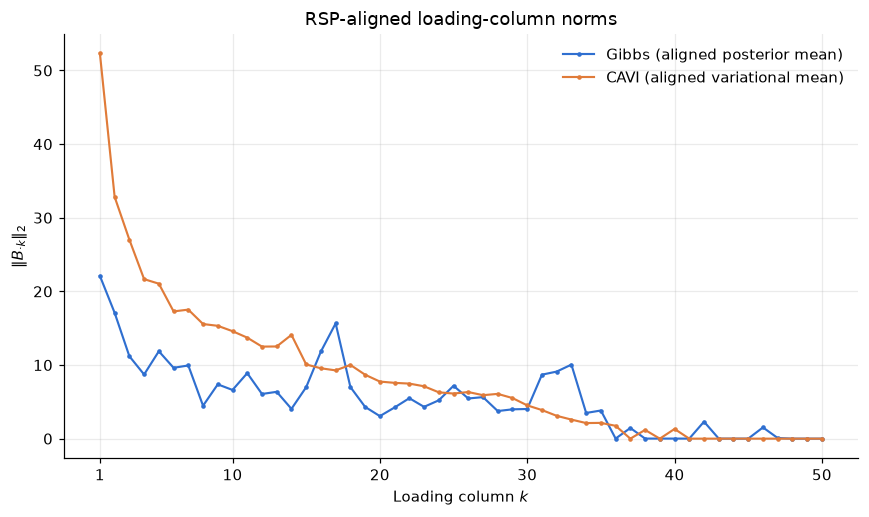

In [10]:
column_index = np.arange(1, K + 1)
norm_gs = np.linalg.norm(np.asarray(gs.B_hat_, dtype=np.float64), axis=0)
norm_vi = np.linalg.norm(np.asarray(vi.mu_aligned_, dtype=np.float64), axis=0)

fig, ax = plt.subplots(figsize=(8, 4.8))
for norms, label, color in (
    (norm_gs, "Gibbs (aligned posterior mean)", "#2f6fd0"),
    (norm_vi, "CAVI (aligned variational mean)", "#e07b39"),
):
    ax.plot(column_index, norms, color=color, lw=1.4, marker=".", ms=4, label=label)
ax.set_title("RSP-aligned loading-column norms")
ax.set_xlabel("Loading column $k$")
ax.set_ylabel(r"$\|B_{\cdot k}\|_2$")
ax.set_xticks([1, 10, 20, 30, 40, 50])
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

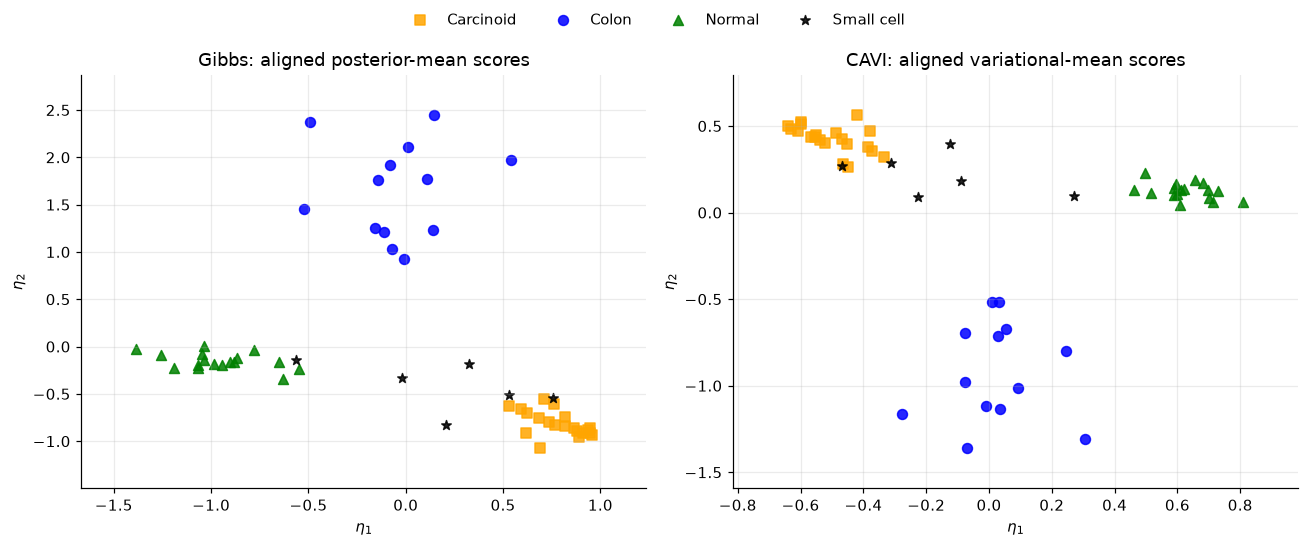

In [11]:
def plot_factor_scores(ax, eta, title):
    for label, start, stop, color, marker in GROUPS:
        ax.scatter(
            eta[0, start:stop],
            eta[1, start:stop],
            c=color,
            marker=marker,
            s=42,
            alpha=0.85,
            label=label,
        )
    ax.set_title(title)
    ax.set_xlabel(r"$\eta_1$")
    ax.set_ylabel(r"$\eta_2$")
    ax.margins(x=0.12, y=0.12)


fig, axes = plt.subplots(1, 2, figsize=(12, 5.0))
plot_factor_scores(axes[0], eta_gs_mean, "Gibbs: aligned posterior-mean scores")
plot_factor_scores(axes[1], eta_vi_mean, "CAVI: aligned variational-mean scores")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=4, frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.94))
plt.show()

## 7. Run Summary

The following summary is generated from the actual run. Factor counts in the original coordinates reflect the marginal-interval rule under the MGP prior; RSP status describes only the post-processing and does not alter the fitted results in those coordinates.

In [12]:
print("Lung cancer analysis summary (MGP prior)")
print("=" * 40)
print(f"Settings: K={K}, nu=3, a1=2.1, a2=3.1, a_sigma=1, b_sigma=1")
print(
    f"Gibbs: {S} kept draws, active factors={r_gs}, "
    f"fit wall={gs_wall:.1f}s, RSP status={alignment_summary['Gibbs']['status']}"
)
print(
    f"CAVI: {vi.n_iter_} sweeps, converged={vi.converged_} ({vi.stop_reason_}), "
    f"active factors={r_vi}, fit wall={vi_wall:.1f}s, "
    f"RSP status={alignment_summary['CAVI']['status']}"
)
print(
    f"Bulk ESS median (200-gene subset): "
    f"B={ess_gs['B']['median']:.1f}, sigma2={ess_gs['sigma2']['median']:.1f}"
)
print("All requested fits, figures, and numerical checks completed.")

Lung cancer analysis summary (MGP prior)
Settings: K=50, nu=3, a1=2.1, a2=3.1, a_sigma=1, b_sigma=1
Gibbs: 1000 kept draws, active factors=37, fit wall=3133.9s, RSP status=1
CAVI: 1000 sweeps, converged=False (max_iter), active factors=38, fit wall=260.3s, RSP status=1
Bulk ESS median (200-gene subset): B=921.4, sigma2=930.5
All requested fits, figures, and numerical checks completed.
